<a href="https://colab.research.google.com/github/Mifa-Miftahul/pm-turi4-clustering-MifaMiftahul/blob/main/PM_P9_MifaMiftahulFalaah_2488010072.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Langkah 1 — Menyiapkan data & scaling (wajib).

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler

df = pd.DataFrame({
    'usia': [20, 22, 25, 30, 35, 40, 45, 50, 55],
    'pendapatan': [
        3000000, 3500000, 4000000,
        5000000, 6000000, 7000000,
        8000000, 9000000, 10000000
    ],
    'skor_belanja': [85, 90, 80, 70, 65, 55, 45, 35, 25]
})

print("Dataset Pelanggan:")
print(df)

X = df[['usia', 'pendapatan', 'skor_belanja']]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

df_scaled = pd.DataFrame(
    X_scaled,
    columns=['usia', 'pendapatan', 'skor_belanja']
)

print("\nData Setelah Scaling:")
print(df_scaled.round(2))

Dataset Pelanggan:
   usia  pendapatan  skor_belanja
0    20     3000000            85
1    22     3500000            90
2    25     4000000            80
3    30     5000000            70
4    35     6000000            65
5    40     7000000            55
6    45     8000000            45
7    50     9000000            35
8    55    10000000            25

Data Setelah Scaling:
   usia  pendapatan  skor_belanja
0 -1.33       -1.34          1.11
1 -1.16       -1.13          1.35
2 -0.91       -0.92          0.88
3 -0.49       -0.49          0.41
4 -0.07       -0.07          0.18
5  0.36        0.35         -0.28
6  0.78        0.78         -0.75
7  1.20        1.20         -1.22
8  1.62        1.63         -1.68


Langkah 2 — Metode Elbow menentukan K.

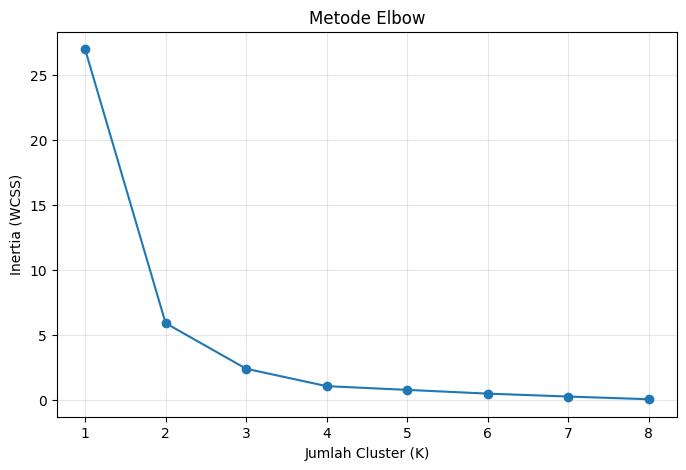

In [16]:
from sklearn.cluster import KMeans

inertias = []

for k in range(1, 9):
    km = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    km.fit(X_scaled)
    inertias.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 9), inertias, marker='o')
plt.xlabel('Jumlah Cluster (K)')
plt.ylabel('Inertia (WCSS)')
plt.title('Metode Elbow')
plt.xticks(range(1, 9))
plt.grid(True, alpha=0.3)
plt.show()

Langkah 3 — Menjalankan K-Means (K=3).

In [17]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df['cluster'] = kmeans.fit_predict(X_scaled)

print("Data pelanggan dengan label cluster:")
print(df)

print("\nJumlah pelanggan setiap cluster:")
print(df['cluster'].value_counts().sort_index())

Data pelanggan dengan label cluster:
   usia  pendapatan  skor_belanja  cluster
0    20     3000000            85        2
1    22     3500000            90        2
2    25     4000000            80        2
3    30     5000000            70        0
4    35     6000000            65        0
5    40     7000000            55        0
6    45     8000000            45        1
7    50     9000000            35        1
8    55    10000000            25        1

Jumlah pelanggan setiap cluster:
cluster
0    3
1    3
2    3
Name: count, dtype: int64


Langkah 4 — Evaluasi silhouette score.

In [18]:
from sklearn.metrics import silhouette_score

score = silhouette_score(X_scaled, df['cluster'])

print("Silhouette Score K=3:", round(score, 4))

Silhouette Score K=3: 0.5136


Langkah 5 — Interpretasi: profil rata-rata tiap cluster.

In [19]:
profil = df.groupby('cluster')[
    ['usia', 'pendapatan', 'skor_belanja']
].mean().round(1)

print("Profil rata-rata setiap cluster:")
print(profil)

Profil rata-rata setiap cluster:
         usia  pendapatan  skor_belanja
cluster                                
0        35.0   6000000.0          63.3
1        50.0   9000000.0          35.0
2        22.3   3500000.0          85.0


D. Latihan mandiri

Langkah 6 - Jalankan K-Means K=5; bandingkan silhouette score dengan K=3.

In [20]:
kmeans_5 = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

label_5 = kmeans_5.fit_predict(X_scaled)

silhouette_5 = silhouette_score(X_scaled, label_5)

print("Silhouette Score K=3:", round(score, 4))
print("Silhouette Score K=5:", round(silhouette_5, 4))

if silhouette_5 > score:
    print("K=5 memiliki silhouette score lebih tinggi.")
elif silhouette_5 < score:
    print("K=3 memiliki silhouette score lebih tinggi.")
else:
    print("K=3 dan K=5 memiliki silhouette score yang sama.")

Silhouette Score K=3: 0.5136
Silhouette Score K=5: 0.3361
K=3 memiliki silhouette score lebih tinggi.


Langkah 7 - Jalankan K-Means tanpa scaling (K=3); bandingkan silhouette-nya. Apa kesimpulannya?

In [21]:
kmeans_tanpa_scaling = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

label_tanpa_scaling = kmeans_tanpa_scaling.fit_predict(X)

score_tanpa_scaling = silhouette_score(
    X,
    label_tanpa_scaling
)

print("Silhouette dengan scaling   :", round(score, 4))
print("Silhouette tanpa scaling    :", round(score_tanpa_scaling, 4))

Silhouette dengan scaling   : 0.5136
Silhouette tanpa scaling    : 0.5074


Kesimpulannya:
Pada percobaan K-Means dengan K=3, scaling digunakan untuk menyetarakan skala fitur usia, pendapatan, dan skor belanja. Tanpa scaling, pendapatan yang memiliki rentang nilai lebih besar dapat mendominasi perhitungan jarak, sehingga pengelompokan lebih banyak dipengaruhi oleh fitur tersebut. Dampak scaling dapat diamati dengan membandingkan silhouette score sebelum dan sesudah scaling. Karena itu, scaling penting agar setiap fitur memiliki pengaruh yang lebih seimbang dalam proses clustering.

Langkah 8 — Membuat Scatter Plot Cluster

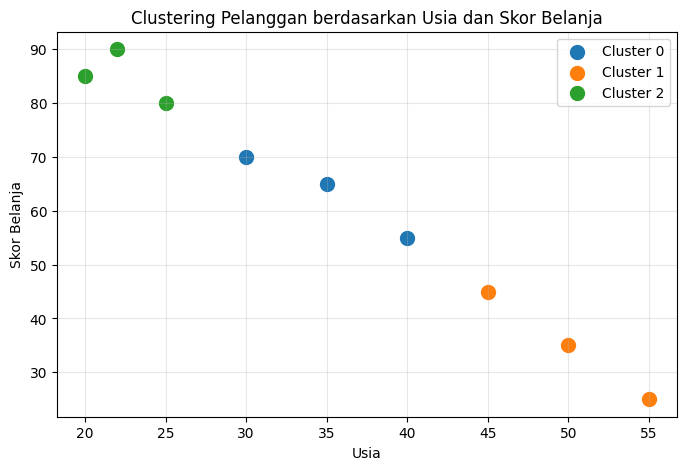

In [22]:
plt.figure(figsize=(8, 5))

for cluster in sorted(df['cluster'].unique()):
    data_cluster = df[df['cluster'] == cluster]

    plt.scatter(
        data_cluster['usia'],
        data_cluster['skor_belanja'],
        label=f'Cluster {cluster}',
        s=100
    )

plt.xlabel('Usia')
plt.ylabel('Skor Belanja')
plt.title('Clustering Pelanggan berdasarkan Usia dan Skor Belanja')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

E. Refleksi

9. K-Means mengelompokkan data tanpa label berdasarkan kedekatan jarak antar-data. Algoritma ini terlebih dahulu menentukan centroid awal, lalu menempatkan setiap data ke dalam cluster dengan centroid terdekat. Setelah itu, centroid diperbarui berdasarkan rata-rata anggota masing-masing cluster. Langkah-langkah ini diulang hingga posisi centroid stabil atau konvergen.


10. Metode Elbow menunjukkan titik siku pada K=3. Hingga jumlah cluster tersebut, penambahan cluster menurunkan inertia secara signifikan, sedangkan penambahan cluster setelahnya hanya menghasilkan penurunan yang lebih kecil. Karena itu, K=3 dapat dipilih sebagai jumlah cluster yang menyeimbangkan kualitas pengelompokan dan kompleksitas model. Namun, titik siku ini perlu dikonfirmasi melalui grafik hasil praktikum.


11. Scaling penting karena K-Means mengelompokkan data berdasarkan jarak. Jika rentang nilai antarfitur sangat berbeda, fitur dengan nilai besar—seperti pendapatan—dapat lebih mendominasi perhitungan. Akibatnya, hasil pengelompokan lebih dipengaruhi oleh fitur tersebut. Scaling menyetarakan skala fitur sehingga proses clustering menghasilkan pengelompokan yang lebih proporsional.
